# TouNum, livrable 1 : distinguer les photos des autres images

Projet Leyenda, CESI. Rendu de notre groupe pour TouNum : premier module du prototype de légendage automatique
d'images.

Équipe : Mathieu, Matthis et Julien.

---
## 0. Contexte métier et objectif

TouNum numérise des documents (textes, images, etc.) pour ses clients et souhaite ajouter à son offre un
service de légendage automatique des images. TouNum nous a confié la conception de ce service, dont le workflow
comporte trois modules :

1. **Filtrage** : ne garder que les photographies (ce livrable) ;
2. **Prétraitement** : nettoyer les images bruitées ou floues (livrable 2) ;
3. **Captioning** : écrire une légende descriptive pour chaque photo (livrable 3).

Une bonne partie des images déjà numérisées par TouNum ne sont pas des photos : schémas, textes scannés, dessins,
peintures. Les envoyer au module de captioning coûterait du calcul pour produire des légendes sans intérêt. Dans
ce notebook, nous construisons le filtre d'entrée : un réseau de neurones qui répond « photo » (1) ou « autre » (0).

### Plan
| Section | Contenu |
|---|---|
| 1 | Environnement et reproductibilité |
| 2 | Les données : inventaire, exploration, échantillonnage |
| 3 | Découpage entraînement / validation / test |
| 4 | Difficulté croissante : texte, puis schémas, dessins et peintures |
| 5 | Architecture du réseau : schéma, paramètres, fonction de perte, optimiseur |
| 6 | Entraînement : courbes de perte et d'accuracy (entraînement et validation) |
| 7 | Analyse biais / variance (sous-apprentissage et sur-apprentissage) |
| 8 | Améliorations : augmentation, dropout, L2, early stopping |
| 9 | Évaluation finale sur un jeu de test équilibré et un jeu réaliste, erreurs, seuil |
| 10 | Comparaison avec un réseau pré-entraîné (MobileNetV2) et choix du modèle de production |
| 11 | Conclusion, limites et suites |

### Exécution
Le notebook se lance avec `bash scripts/run_notebook.sh 1 full`, qui reconstruit le `.ipynb` à partir de ce
fichier `.py` et l'exécute. Pour l'ouvrir en mode interactif : `uv run --with jupyterlab jupyter lab`.
À la première exécution, les images échantillonnées sont extraites des archives et mises en cache dans `data/`
(quelques minutes) ; les exécutions suivantes lisent le cache. `bash scripts/run_notebook.sh 1 quick` lance une
version très courte (2 époques) pour vérifier que tout s'exécute. Elle écrit un fichier `.quick.ipynb` séparé et
ne touche jamais au livrable.

## 1. Environnement et reproductibilité

In [1]:
import os
import sys
import time
import inspect
import tempfile
from pathlib import Path

os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "3")      # masque les logs C++ de TensorFlow (autotuning GPU)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))                   # le code réutilisable est dans src/tounum_cls
import tounum_gpu
tounum_gpu.setup()                                      # utilise le GPU NVIDIA s'il y en a un (src/tounum_gpu.py)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from IPython.display import display, Markdown
import tensorflow as tf
import keras
import sklearn

from tounum_cls import config, data, modeling, evaluation

QUICK = os.environ.get("TOUNUM_QUICK") == "1"
# Nombre d'époques de chaque expérience (réduit en mode QUICK)
EPOCHS = {"stage": 8, "main": 20, "curve": 20, "improve": 25, "mobilenet": 8}
if QUICK:
    EPOCHS = {k: 2 for k in EPOCHS}

keras.utils.set_random_seed(config.SEED)                # fixe la graine de Python, NumPy et TensorFlow
pd.set_option("display.precision", 3)
pd.set_option("display.width", 140)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 100


def milliers(n):
    """Entier avec une espace comme séparateur de milliers (12 000)."""
    return f"{int(n):,}".replace(",", " ")


print(f"Python {sys.version.split()[0]} | TensorFlow {tf.__version__} | Keras {keras.__version__} | "
      f"scikit-learn {sklearn.__version__} | pandas {pd.__version__} | numpy {np.__version__}")
print("GPU :", tf.config.list_physical_devices("GPU") or "aucun (exécution sur CPU)")
print(f"Graine : {config.SEED} | mode QUICK : {QUICK} | époques : {EPOCHS}")

I0000 00:00:1791361641.600809  209413 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1791361642.128752  209413 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


Python 3.12.13 | TensorFlow 2.21.0 | Keras 3.15.1 | scikit-learn 1.9.1 | pandas 3.0.6 | numpy 2.5.3
GPU : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Graine : 42 | mode QUICK : False | époques : {'stage': 8, 'main': 20, 'curve': 20, 'improve': 25, 'mobilenet': 8}


Toutes les sources d'aléatoire (échantillonnage des images, découpage, initialisation des poids, mélange des
batchs) dépendent de la graine `SEED = 42`. TensorFlow peut malgré tout donner de petites différences d'une
exécution à l'autre, sur CPU et plus encore sur GPU, parce que les opérations parallèles ne sont pas toujours
sommées dans le même ordre. Les dernières décimales peuvent bouger, et un diagnostic situé juste sur un seuil peut
basculer.

## 2. Les données

TouNum nous a fourni cinq archives, une par type d'image. Le nom de l'archive donne l'étiquette : il n'y a pas de
fichier d'annotation. Notre cible binaire est `Photo` = **1** et tout le reste = **0**. Dans la suite, les classes
gardent le nom de leur archive : `Photo` (photos), `Painting` (peintures), `Schematics` (schémas et graphes),
`Sketch` (portraits dessinés en noir et blanc) et `Text` (textes scannés).

Les archives pèsent plusieurs Go, donc `prepare_dataset()` ne les décompresse pas en entier. La fonction :
1. liste les images (jpg/png seulement, ce qui écarte les fichiers parasites comme `desktop.ini`) ;
2. tire un échantillon reproductible formé de deux parties disjointes : un pool de modélisation équilibré et un
   jeu de test étendu ;
3. n'extrait que les fichiers échantillonnés ;
4. les charge avec **ImageIO**, les convertit en **RGB** (les dessins sont en niveaux de gris), les
   redimensionne en **128×128** et les stocke en `uint8` dans un cache (`data/cache`).

In [2]:
t0 = time.perf_counter()
X, meta = data.prepare_dataset()
print(f"X : {X.shape}, dtype={X.dtype}, {X.nbytes / 1e6:.0f} Mo en mémoire | chargé en {time.perf_counter() - t0:.0f} s")

summary = meta.groupby(["source", "subset"]).size().unstack(fill_value=0)
summary["total échantillonné"] = summary.sum(axis=1)
display(summary.loc[config.CLASSES])

X : (16605, 128, 128, 3), dtype=uint8, 816 Mo en mémoire | chargé en 0 s


subset,ext,pool,total échantillonné
source,,,
Photo,1000,6000,7000
Painting,999,2800,3799
Schematics,1000,1200,2200
Text,1000,1200,2200
Sketch,606,800,1406


**Pourquoi un échantillon plutôt que les 41 400 images ?** Ce notebook entraîne une quinzaine de réseaux (étapes,
capacités, courbe d'apprentissage, régularisation), donc le pool de modélisation doit rester assez petit pour que
cela reste rapide. Notre première version, entraînée sur CPU, utilisait 6 000 images, et sa courbe
d'apprentissage (section 7.2) montait encore à pleine taille : davantage d'images aidait encore. L'entraînement
tourne maintenant sur GPU, nous avons donc doublé le pool à 12 000 images (6 000 photos et 6 000 non-photos). Aller
plus loin coûterait surtout du temps d'extraction et de chargement (certaines peintures dépassent 60 mégapixels).
Les effectifs se règlent dans `src/tounum_cls/config.py` (`POOL_COUNTS`, `EXT_COUNTS`).

- Le **pool** est réparti à 50/50 entre photos et non-photos. Les peintures ont la plus grande part des négatifs
  (2 800 sur 6 000) parce que c'est la classe la plus difficile.
- Le **jeu de test étendu** (`ext`) ne sert jamais à entraîner, à choisir un modèle ou à fixer un seuil. Il est
  volontairement déséquilibré (environ 22 % de photos) pour estimer les performances sur une archive qui ressemble
  aux vraies données d'un client.

### 2.1 Taille d'origine des images
Les images arrivent dans des tailles et des formats très variés. Seuls les en-têtes des fichiers sont lus ici, ce
qui est rapide.

In [3]:
def original_size(path):
    with Image.open(path) as im:
        return im.size  # (largeur, hauteur)

sizes = meta["path"].map(original_size)
meta["width"] = [s[0] for s in sizes]
meta["height"] = [s[1] for s in sizes]
meta["megapixels"] = meta["width"] * meta["height"] / 1e6
display(meta.groupby("source")[["width", "height", "megapixels"]].median().loc[config.CLASSES]
        .rename(columns={"width": "largeur", "height": "hauteur", "megapixels": "mégapixels"}))
print("Chaque image est redimensionnée en 128x128 sans garder ses proportions. Les images très allongées (pages A4 "
      "de texte) sont déformées, ce qui reste acceptable pour une simple décision photo / non-photo.")

,largeur,hauteur,mégapixels
source,,,
Photo,640.0,480.0,0.273
Painting,801.0,800.0,0.706
Schematics,675.0,461.5,0.314
Text,595.0,842.0,0.501
Sketch,1111.0,1111.0,1.234


Chaque image est redimensionnée en 128x128 sans garder ses proportions. Les images très allongées (pages A4 de texte) sont déformées, ce qui reste acceptable pour une simple décision photo / non-photo.


### 2.2 Ce que voit le réseau (images 128×128)

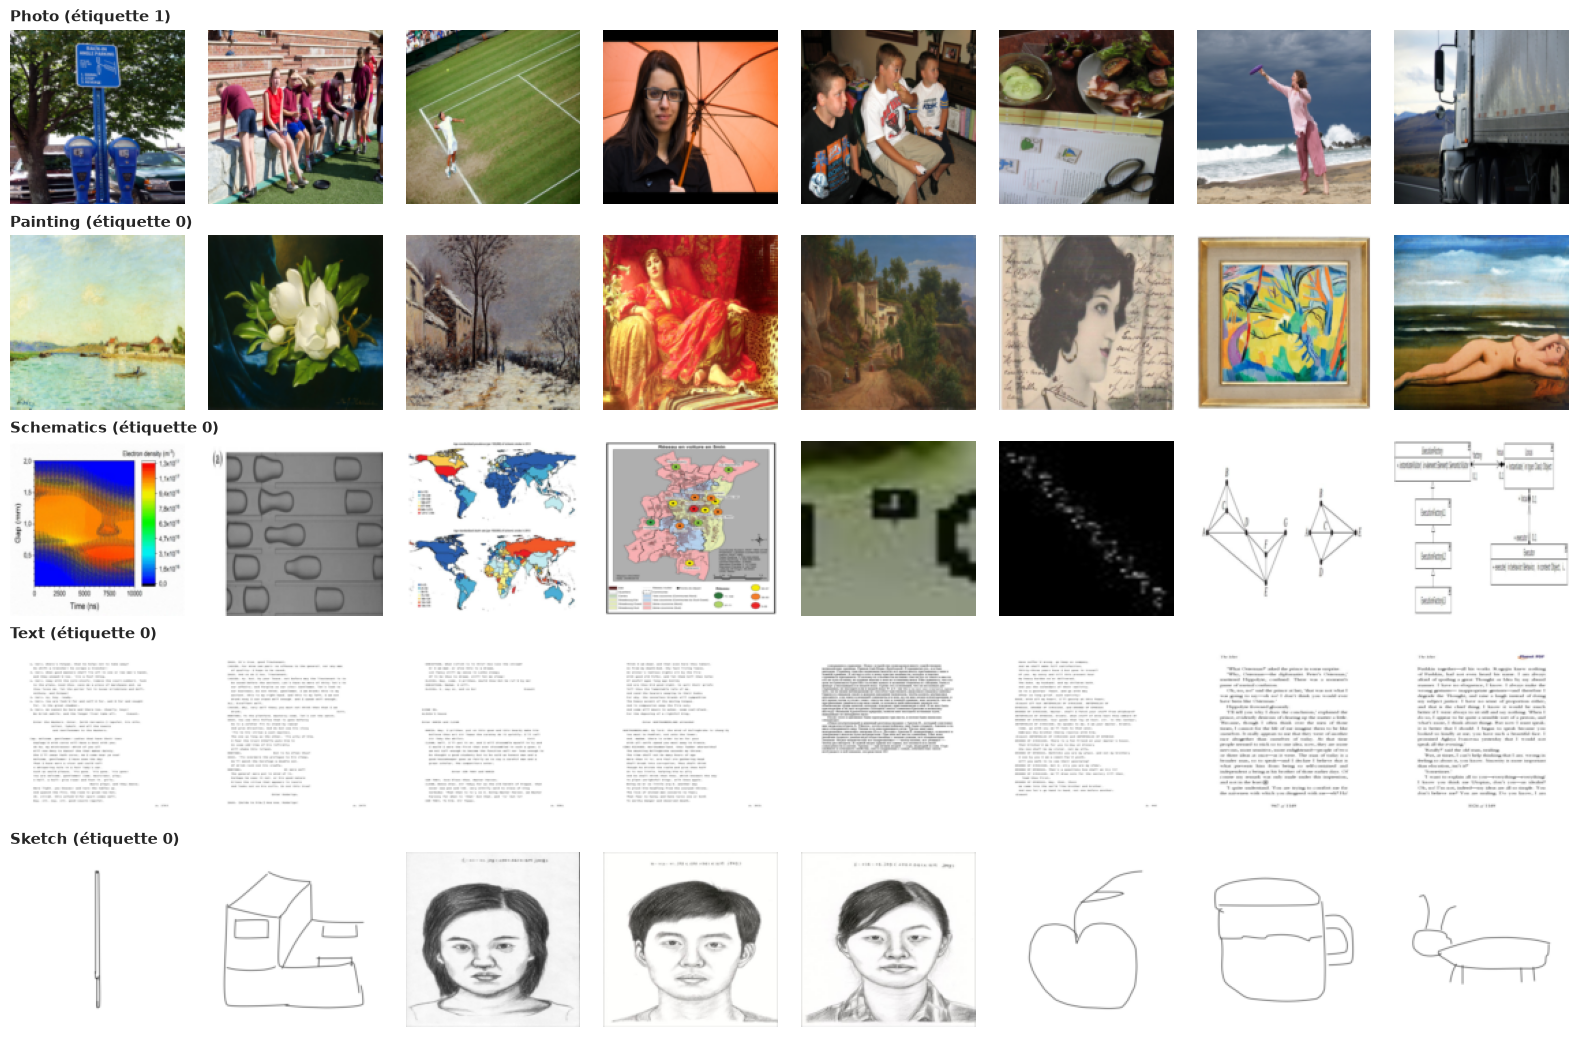

In [4]:
rng = np.random.default_rng(config.SEED)
fig, axes = plt.subplots(len(config.CLASSES), 8, figsize=(16, 2.1 * len(config.CLASSES)))
for r, source in enumerate(config.CLASSES):
    idx = rng.choice(meta.index[(meta["source"] == source) & (meta["subset"] == "pool")], 8, replace=False)
    for c, i in enumerate(idx):
        axes[r, c].imshow(X[i])
        axes[r, c].axis("off")
    axes[r, 0].set_title(source + (" (étiquette 1)" if source == config.POSITIVE_CLASS else " (étiquette 0)"),
                         loc="left", fontsize=11, fontweight="bold")
plt.tight_layout()
plt.show()

### 2.3 Deux statistiques simples qui séparent déjà certaines classes
La **luminosité** moyenne et la **colorimétrie** (écart moyen entre les canaux R, G et B, qui vaut 0 pour une
image en niveaux de gris). Elles donnent une idée de la difficulté de chaque séparation.

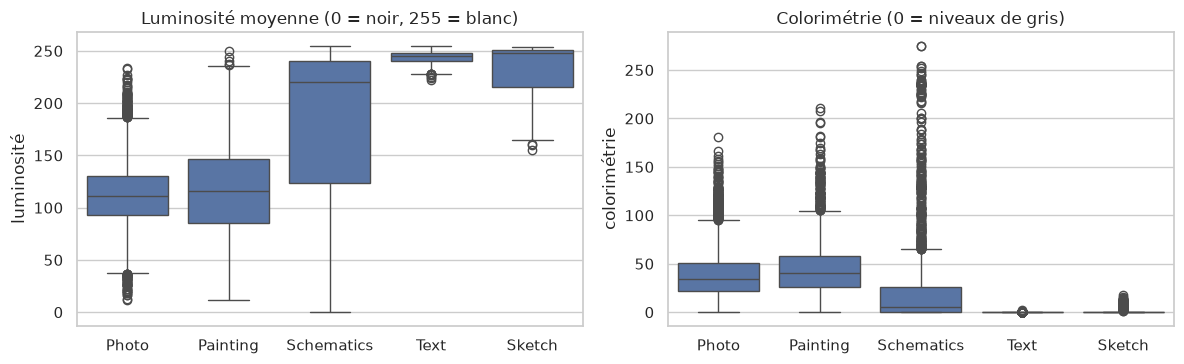

In [5]:
pix = X.astype(np.float32)
meta["brightness"] = pix.mean(axis=(1, 2, 3))
meta["colourfulness"] = (np.abs(pix[..., 0] - pix[..., 1]) + np.abs(pix[..., 1] - pix[..., 2])).mean(axis=(1, 2))
del pix

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
sns.boxplot(data=meta, x="source", y="brightness", order=config.CLASSES, ax=axes[0])
axes[0].set_title("Luminosité moyenne (0 = noir, 255 = blanc)")
axes[0].set_ylabel("luminosité")
sns.boxplot(data=meta, x="source", y="colourfulness", order=config.CLASSES, ax=axes[1])
axes[1].set_title("Colorimétrie (0 = niveaux de gris)")
axes[1].set_ylabel("colorimétrie")
for ax in axes:
    ax.set_xlabel("")
plt.tight_layout()
plt.show()

In [6]:
medians = meta.groupby("source")[["brightness", "colourfulness"]].median().loc[config.CLASSES]
display(Markdown(
    "**Résultats.** Luminosité médiane : "
    + ", ".join(f"{s} {medians.loc[s, 'brightness']:.0f}" for s in config.CLASSES)
    + ". Colorimétrie médiane : "
    + ", ".join(f"{s} {medians.loc[s, 'colourfulness']:.1f}" for s in config.CLASSES) + "."
))

**Résultats.** Luminosité médiane : Photo 111, Painting 116, Schematics 220, Text 245, Sketch 248. Colorimétrie médiane : Photo 34.2, Painting 40.4, Schematics 5.2, Text 0.0, Sketch 0.0.

Les textes scannés et les dessins sont très clairs et presque sans couleur, et les schémas sont en général clairs
mais plus variables (certains sont sombres ou colorés). Un classifieur très simple, avec des seuils sur ces deux
nombres, en séparerait déjà une bonne partie.
Les peintures sont un autre problème : leurs plages de luminosité et de couleur recouvrent celles des photos. On
ne peut les distinguer que par la texture et la structure, ce qu'un réseau convolutif sait justement capter. C'est
pourquoi la section 4 va des classes les plus faciles aux plus difficiles.

## 3. Découpage entraînement / validation / test

Le pool est découpé avec une stratification sur la **classe source** (et pas seulement sur l'étiquette binaire),
pour que chaque type d'image ait la même part dans les trois jeux :

| Jeu | Part | Rôle |
|---|---|---|
| `train` | 70 % | apprendre les poids du réseau |
| `val` (validation) | 15 % | suivre l'entraînement époque par époque, régler et choisir le modèle. C'est l'« erreur de test » tracée en section 6 |
| `test` | 15 % | mesure finale uniquement : jamais utilisé pour entraîner, choisir un modèle ou fixer un seuil (sections 4 et 9) |
| `ext` | n/a | jeu de test étendu et déséquilibré, hors du pool, utilisé comme `test` |

Choisir le modèle en regardant le jeu de test ferait fuiter de l'information dans ce choix et rendrait l'accuracy
annoncée trop optimiste. D'où des jeux de validation et de test séparés.

In [7]:
split_table = pd.crosstab(meta["source"], meta["split"]).loc[config.CLASSES, ["train", "val", "test", "ext"]]
split_table.loc["TOTAL"] = split_table.sum()
display(split_table)

# contrôle de fuite : aucun fichier ne doit apparaître dans deux jeux
members = {s: set(meta.loc[meta["split"] == s, "member"]) for s in ["train", "val", "test", "ext"]}
for a in members:
    for b in members:
        if a < b:
            assert not (members[a] & members[b]), f"fuite de données entre {a} et {b}"
print("OK : train / val / test / ext sont disjoints deux à deux.")

split,train,val,test,ext
source,,,,
Photo,4200,900,900,1000
Painting,1960,420,420,999
Schematics,840,180,180,1000
Text,840,180,180,1000
Sketch,560,120,120,606
TOTAL,8400,1800,1800,4605


OK : train / val / test / ext sont disjoints deux à deux.


Deux fonctions utilitaires servent dans tout le notebook : récupérer les données d'une étape, et lancer un
entraînement chronométré.

In [8]:
def get_split(negative_sources=None):
    """{'train': (X, y, meta), 'val': ..., 'test': ...}. Les photos sont toujours incluses ;
    `negative_sources` choisit les classes négatives (None = toutes)."""
    return {s: data.select(X, meta, s, negative_sources) for s in ("train", "val", "test")}


def run(split, epochs, early_stopping=False, patience=4, **model_kwargs):
    """Construit un CNN (`model_kwargs` passés à modeling.build_cnn), l'entraîne, renvoie (modèle, historique, secondes)."""
    keras.utils.set_random_seed(config.SEED)
    Xtr, ytr, _ = split["train"]
    Xva, yva, _ = split["val"]
    model = modeling.build_cnn(**model_kwargs)
    t0 = time.perf_counter()
    hist = modeling.train(
        model,
        data.make_dataset(Xtr, ytr, shuffle=True),
        data.make_dataset(Xva, yva),
        epochs=epochs,
        class_weight=data.class_weights(ytr),
        early_stopping=early_stopping,
        patience=patience,
        verbose=0,
    )
    return model, hist, time.perf_counter() - t0

## 4. Difficulté croissante

L'énoncé conseille de commencer par les images les plus faciles à distinguer des photos. Nous entraînons **le
même réseau** (décrit en section 5) sur quatre problèmes de difficulté croissante, en ajoutant un type d'image
négatif à chaque étape :

| Étape | Photos contre |
|---|---|
| 1 | textes scannés |
| 2 | textes + schémas |
| 3 | textes + schémas + dessins |
| 4 | textes + schémas + dessins + **peintures** (le problème final) |

Aux étapes 1 à 3, il y a plus de photos que de négatifs : nous utilisons donc des **poids de classe**
(`class_weight`) et nous donnons l'**accuracy équilibrée** (moyenne des rappels des deux classes) plutôt que
l'accuracy brute. Chaque étape est évaluée sur son propre jeu `test`, que l'entraînement ne voit jamais.

In [9]:
stage_rows, stage_per_source, stage_models = [], {}, {}
for stage, negatives in config.STAGES.items():
    split = get_split(negatives)
    model, hist, seconds = run(split, EPOCHS["stage"], early_stopping=True, patience=3)
    Xte, yte, mte = split["test"]
    proba = modeling.predict_proba(model, Xte)
    res = evaluation.evaluate_binary(yte, proba)
    per_src = evaluation.per_source_accuracy(mte, proba)
    worst = per_src.iloc[0]
    stage_rows.append({
        "étape": stage, "n_train": len(split["train"][1]), "époques": len(hist), "temps (s)": round(seconds),
        "acc. équilibrée": res["balanced_accuracy"], "précision": res["precision"], "rappel": res["recall"],
        "F1": res["f1"], "ROC-AUC": res["roc_auc"], "classe la plus difficile": worst["source"],
        "accuracy sur cette classe": worst["accuracy"],
    })
    stage_per_source[stage] = per_src.set_index("source")["accuracy"]
    stage_models[stage] = model
stage_df = pd.DataFrame(stage_rows).set_index("étape")
display(stage_df)

,n_train,époques,temps (s),acc. équilibrée,précision,rappel,F1,ROC-AUC,classe la plus difficile,accuracy sur cette classe
étape,,,,,,,,,,
1_photo_vs_text,5040,8,13,1.000,1.000,1.000,1.000,1.000,Photo,1.000
2_+schematics,5880,8,10,0.954,0.976,0.967,0.972,0.989,Schematics,0.883
3_+sketch,6440,8,10,0.963,0.970,0.982,0.976,0.992,Schematics,0.850
4_+painting,8400,8,10,0.893,0.895,0.890,0.892,0.956,Painting,0.819


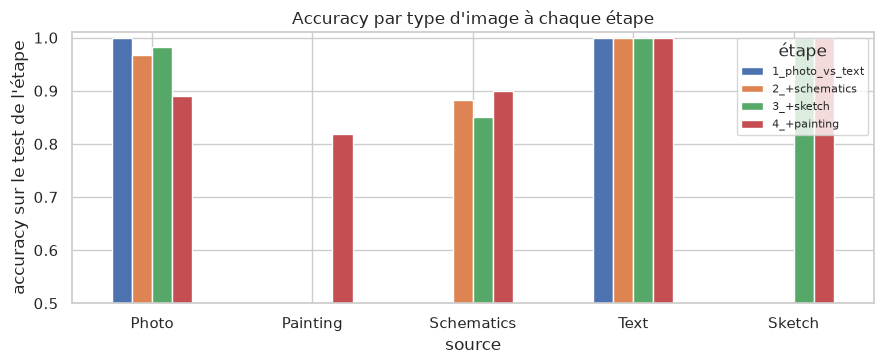

In [10]:
fig, ax = plt.subplots(figsize=(9, 3.8))
pd.DataFrame(stage_per_source).loc[config.CLASSES].plot.bar(ax=ax, rot=0)
ax.set_ylim(0.5, 1.01)
ax.set_ylabel("accuracy sur le test de l'étape")
ax.set_title("Accuracy par type d'image à chaque étape")
ax.legend(title="étape", fontsize=8)
plt.tight_layout()
plt.show()

In [11]:
last = stage_df.iloc[-1]
first = stage_df.iloc[0]
display(Markdown(
    f"**Résultats.** Étape 1 (photo contre texte) : accuracy équilibrée **{first['acc. équilibrée']:.3f}**. "
    f"Étape 4 (toutes les classes, peintures comprises) : **{last['acc. équilibrée']:.3f}**, F1 **{last['F1']:.3f}**. "
    f"À l'étape 4, la classe la plus difficile est **{last['classe la plus difficile']}** "
    f"(accuracy {last['accuracy sur cette classe']:.3f}). "
    + ("C'est ce que nous attendions : les peintures réalistes ressemblent à des photos et concentrent la plupart "
       "des erreurs."
       if last["classe la plus difficile"] == "Painting"
       else "Contrairement à ce que nous attendions, les peintures ne sont pas la principale source d'erreurs. "
            "Ce point demande un examen plus poussé.")
))

**Résultats.** Étape 1 (photo contre texte) : accuracy équilibrée **1.000**. Étape 4 (toutes les classes, peintures comprises) : **0.893**, F1 **0.892**. À l'étape 4, la classe la plus difficile est **Painting** (accuracy 0.819). C'est ce que nous attendions : les peintures réalistes ressemblent à des photos et concentrent la plupart des erreurs.

## 5. Architecture du réseau

Nous utilisons un **réseau de neurones convolutif (CNN)** que nous avons conçu pour ce problème. Le code imprimé
ci-dessous est celui qui sert réellement dans tout le notebook (`src/tounum_cls/modeling.py`).

In [12]:
print(inspect.getsource(modeling._compile))   # perte, optimiseur, métriques
print(inspect.getsource(modeling.build_cnn))  # architecture

def _compile(model: keras.Model, learning_rate: float = 1e-3) -> keras.Model:
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
        loss="binary_crossentropy",
        metrics=["accuracy", keras.metrics.AUC(name="auc")],
    )
    return model

def build_cnn(
    filters: tuple[int, ...] = (16, 32, 64, 128),
    dense_units: int = 64,
    dropout: float = 0.0,
    l2: float = 0.0,
    augmentation: bool = False,
    img_size: int = config.IMG_SIZE,
    learning_rate: float = 1e-3,
    bn_momentum: float = 0.9,
    name: str = "cnn_photo",
) -> keras.Model:
    """CNN conçu par nous pour photo (1) contre non-photo (0).

    Entrée : images uint8 (img_size, img_size, 3) ; la mise à l'échelle /255 est faite DANS le modèle.
    Un bloc = Conv2D 3x3 (padding same) -> BatchNormalization -> ReLU -> MaxPooling2D 2x2.
    Tête : GlobalAveragePooling2D -> Dense(dense_units, relu) -> [Dropout] -> Dense(1, sigmoid).
    `augmentation=True` ajoute des tran

In [13]:
baseline = modeling.build_cnn()
baseline.summary()

Model: "cnn_photo"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image (InputLayer)              │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1 (Conv2D)                  │ (None, 128, 128, 16)   │           432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn1 (BatchNormalization)        │ (None, 128, 128, 16)   │            64 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu1 (Activation)              │ (None, 128, 128, 16)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool1 (MaxPooling2D)            │ (None, 64, 64, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv2D)                  │ (None, 64, 64, 32)     │         4,608 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn2 (BatchNormalization)        │ (None, 64, 64, 32)     │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu2 (Activation)              │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool2 (MaxPooling2D)            │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3 (Conv2D)                  │ (None, 32, 32, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn3 (BatchNormalization)        │ (None, 32, 32, 64)     │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu3 (Activation)              │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool3 (MaxPooling2D)            │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv4 (Conv2D)                  │ (None, 16, 16, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn4 (BatchNormalization)        │ (None, 16, 16, 128)    │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu4 (Activation)              │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool4 (MaxPooling2D)            │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gap (GlobalAveragePooling2D)    │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 106,481 (415.94 KB)

 Trainable params: 106,001 (414.07 KB)

 Non-trainable params: 480 (1.88 KB)

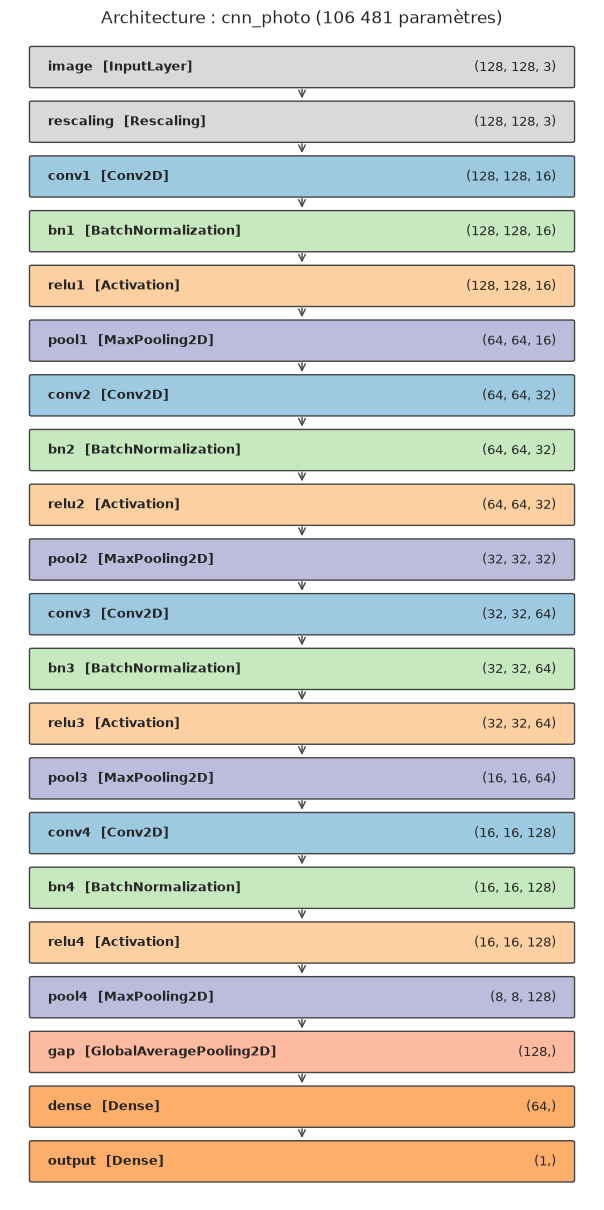

In [14]:
fig = evaluation.draw_architecture(baseline)
plt.show()

### 5.1 Rôle de chaque couche

| Couche | Rôle |
|---|---|
| `Rescaling(1/255)` | ramène les pixels de [0, 255] à [0, 1]. Elle est dans le modèle, donc le code de production peut lui donner des images brutes |
| `Conv2D 3×3` ×4 (16, 32, 64, 128 filtres) | détecte des motifs locaux : contours et textures dans les premiers blocs, formes plus complexes dans les derniers. Les filtres sont appris, contrairement aux filtres de convolution fixés à la main du livrable 2 |
| `BatchNormalization` | normalise les activations de chaque batch, ce qui rend l'entraînement plus rapide et plus stable |
| `ReLU` | la non-linéarité `max(0, x)` |
| `MaxPooling2D 2×2` | divise la résolution par deux : moins de calcul et une certaine tolérance aux petits décalages |
| `GlobalAveragePooling2D` | moyenne chaque carte de features en un seul nombre. Cela évite une énorme couche dense : le modèle a peu de paramètres et sur-apprend moins |
| `Dense(64, ReLU)` | combine les 128 features |
| `Dense(1, sigmoid)` | sortie : la probabilité *P(photo)* dans [0, 1] |

### 5.2 Paramètres du réseau

In [15]:
rows = []
for layer in baseline.layers:
    rows.append({
        "couche": layer.name, "type": type(layer).__name__,
        "forme de sortie": str(tuple(layer.output.shape)[1:]), "paramètres": layer.count_params(),
    })
param_table = pd.DataFrame(rows)
display(param_table[param_table["paramètres"] > 0])
trainable = int(sum(np.prod(w.shape) for w in baseline.trainable_weights))
non_trainable = int(sum(np.prod(w.shape) for w in baseline.non_trainable_weights))
print(f"Total : {milliers(baseline.count_params())} paramètres, dont {milliers(trainable)} entraînables et "
      f"{milliers(non_trainable)} non entraînables (moyennes et variances glissantes de BatchNorm)")

,couche,type,forme de sortie,paramètres
2,conv1,Conv2D,"(128, 128, 16)",432
3,bn1,BatchNormalization,"(128, 128, 16)",64
6,conv2,Conv2D,"(64, 64, 32)",4608
7,bn2,BatchNormalization,"(64, 64, 32)",128
10,conv3,Conv2D,"(32, 32, 64)",18432
11,bn3,BatchNormalization,"(32, 32, 64)",256
14,conv4,Conv2D,"(16, 16, 128)",73728
15,bn4,BatchNormalization,"(16, 16, 128)",512
19,dense,Dense,"(64,)",8256
20,output,Dense,"(1,)",65


Total : 106 481 paramètres, dont 106 001 entraînables et 480 non entraînables (moyennes et variances glissantes de BatchNorm)


### 5.3 Fonction de perte

La sortie est binaire, nous utilisons donc l'**entropie croisée binaire** (*binary cross-entropy*). Pour une
image d'étiquette réelle $y \in \{0, 1\}$ et une probabilité prédite $\hat{p}$ = P(photo) :

$$\mathcal{L}(y, \hat{p}) = -\big[\, y \log \hat{p} + (1 - y)\log(1 - \hat{p}) \,\big]$$

La perte est moyennée sur le batch. Elle est faible quand le réseau a raison et en est sûr, et très forte quand il
se trompe avec assurance (une peinture classée « photo » à 99 %). C'est la perte naturelle d'une sortie sigmoïde
(maximum de vraisemblance d'une variable de Bernoulli), et elle donne de meilleurs gradients que l'erreur
quadratique.

### 5.4 Algorithme d'optimisation

**Adam** (taux d'apprentissage $10^{-3}$, $\beta_1 = 0.9$, $\beta_2 = 0.999$). Adam est une descente de gradient
stochastique sur des mini-batchs (64 images ici) qui adapte le pas de chaque paramètre à partir d'une moyenne
glissante du gradient (momentum) et de son carré (échelle). C'est un choix par défaut fiable, qui converge vite
sans réglage fin du taux d'apprentissage. Nous suivons l'**accuracy** (part des images bien classées au seuil
0.5) et l'**AUC** (capacité à classer les photos au-dessus des non-photos, quel que soit le seuil).

### 5.5 Pourquoi cette architecture ?
- **Un CNN plutôt qu'un réseau dense** : le partage des filtres sur toute l'image exploite sa structure 2D avec
  très peu de paramètres (environ 106 000, contre des millions pour un réseau dense sur 128×128×3 pixels).
- **Un petit réseau** : la tâche est une seule décision globale, et un petit réseau s'entraîne assez vite pour être
  réentraîné de nombreuses fois lors des comparaisons des sections 4, 7 et 8.
- **Appuyé par les résultats** : la section 7 compare ce réseau à une version beaucoup plus petite et à une plus
  grande, et la section 10 à un réseau pré-entraîné de plusieurs millions de paramètres.

## 6. Entraînement et courbes d'apprentissage

Nous entraînons le modèle de référence (*baseline*, sans régularisation) sur le problème **final** (étape 4 :
photos contre toutes les autres classes). Les courbes comparent, à chaque époque, l'entraînement et la validation
(l'« erreur de test » de l'énoncé), pour la perte et pour l'accuracy.

In [16]:
FINAL_SPLIT = get_split(None)
Xtr, ytr, mtr = FINAL_SPLIT["train"]
Xva, yva, mva = FINAL_SPLIT["val"]
Xte, yte, mte = FINAL_SPLIT["test"]
print(f"train {Xtr.shape[0]} | val {Xva.shape[0]} | test {Xte.shape[0]} | photos dans train : {ytr.mean():.1%}")

baseline_model, baseline_hist, baseline_sec = run(FINAL_SPLIT, EPOCHS["main"])
print(f"Entraînement terminé en {baseline_sec:.0f} s ({baseline_sec / len(baseline_hist):.1f} s par époque)")
shown = sorted({i for i in (0, 1, 2, len(baseline_hist) // 2, len(baseline_hist) - 1) if i < len(baseline_hist)})
display(baseline_hist.round(4).set_index("epoch").iloc[shown])

train 8400 | val 1800 | test 1800 | photos dans train : 50.0%


Entraînement terminé en 15 s (0.8 s par époque)


,accuracy,auc,loss,val_accuracy,val_auc,val_loss
epoch,,,,,,
1,0.801,0.875,0.426,0.828,0.916,0.374
2,0.838,0.917,0.357,0.863,0.935,0.327
3,0.853,0.931,0.329,0.867,0.950,0.310
11,0.907,0.969,0.224,0.885,0.962,0.276
20,0.929,0.982,0.172,0.908,0.969,0.248


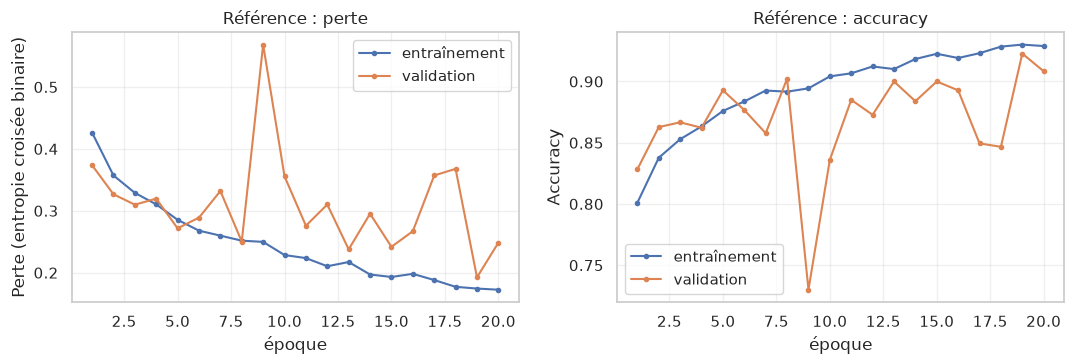

In [17]:
evaluation.plot_history(baseline_hist, "Référence")
plt.show()

In [18]:
diag = evaluation.diagnose_fit(baseline_hist)
display(Markdown(
    f"**Résultats (modèle de référence).** Accuracy finale : entraînement **{diag['train_acc']:.3f}**, "
    f"validation **{diag['val_acc']:.3f}** (écart {diag['gap_acc']:+.3f}). "
    f"Perte finale : entraînement {diag['train_loss']:.3f}, validation {diag['val_loss']:.3f}. "
    f"Perte de validation la plus basse à l'époque **{diag['best_epoch']}** sur {len(baseline_hist)} "
    f"(remontée depuis ce minimum : {diag['val_loss_drift']:+.3f}). Diagnostic : **{diag['verdict']}**."
))

**Résultats (modèle de référence).** Accuracy finale : entraînement **0.929**, validation **0.908** (écart +0.021). Perte finale : entraînement 0.173, validation 0.248. Perte de validation la plus basse à l'époque **19** sur 20 (remontée depuis ce minimum : +0.056). Diagnostic : **variance élevée (sur-apprentissage)**.

**Lecture des courbes.**
- Pendant les premières époques, la courbe de validation peut sauter, parfois fortement, parce que
  `BatchNormalization` utilise des statistiques glissantes qui ont besoin de quelques pas pour se stabiliser. Ce
  n'est pas un défaut du modèle.
- Si la perte d'entraînement continue de baisser alors que la perte de validation remonte, le réseau **apprend par
  cœur** le jeu d'entraînement (sur-apprentissage).
- Si les deux courbes restent hautes, le réseau est **trop simple** ou pas assez entraîné (sous-apprentissage).

## 7. Analyse biais / variance

- **Biais élevé = sous-apprentissage** : le modèle est trop rigide pour capter la structure des données. L'erreur
  est élevée à la fois sur l'entraînement et sur la validation.
- **Variance élevée = sur-apprentissage** : le modèle s'ajuste au bruit des données d'entraînement. L'erreur
  d'entraînement est faible mais l'erreur de validation est nettement plus haute (grand écart).
- Ce que nous cherchons : deux erreurs basses et proches l'une de l'autre.

Un modèle plus complexe réduit le biais mais augmente la variance. Nous le vérifions de deux façons.

Les diagnostics automatiques utilisent des seuils fixes (accuracy d'entraînement sous 0.90 : biais ; écart
entraînement-validation au-dessus de 0.05, ou perte de validation plus de 0.05 au-dessus de son minimum :
variance). Un cas proche d'un seuil peut basculer d'une exécution à l'autre.

### 7.1 Trois capacités de modèle
Mêmes données, même procédure ; seule la taille du réseau change.

In [19]:
CAPACITY = {
    "trop simple": dict(filters=(4, 8), dense_units=4),
    "référence": dict(),
    "trop complexe": dict(filters=(32, 64, 128, 256), dense_units=256),
}
cap_hist, cap_models, cap_rows = {"référence": baseline_hist}, {"référence": baseline_model}, []
for name, kwargs in CAPACITY.items():
    if name == "référence":
        model, hist, sec = baseline_model, baseline_hist, baseline_sec
    else:
        model, hist, sec = run(FINAL_SPLIT, EPOCHS["main"], **kwargs)
        cap_hist[name], cap_models[name] = hist, model
    d = evaluation.diagnose_fit(hist)
    cap_rows.append({"modèle": name, "paramètres": model.count_params(), "acc. entraînement": d["train_acc"],
                     "acc. validation": d["val_acc"], "écart": d["gap_acc"], "perte val. min": hist["val_loss"].min(),
                     "époque du min": d["best_epoch"], "diagnostic": d["verdict"]})
cap_df = pd.DataFrame(cap_rows).set_index("modèle")
display(cap_df)

,paramètres,acc. entraînement,acc. validation,écart,perte val. min,époque du min,diagnostic
modèle,,,,,,,
trop simple,485,0.795,0.766,0.030,0.430,18,biais élevé (sous-apprentissage)
référence,106481,0.929,0.908,0.021,0.193,19,variance élevée (sur-apprentissage)
trop complexe,455905,0.932,0.902,0.030,0.232,19,équilibré (pas de problème net de biais ou de ...


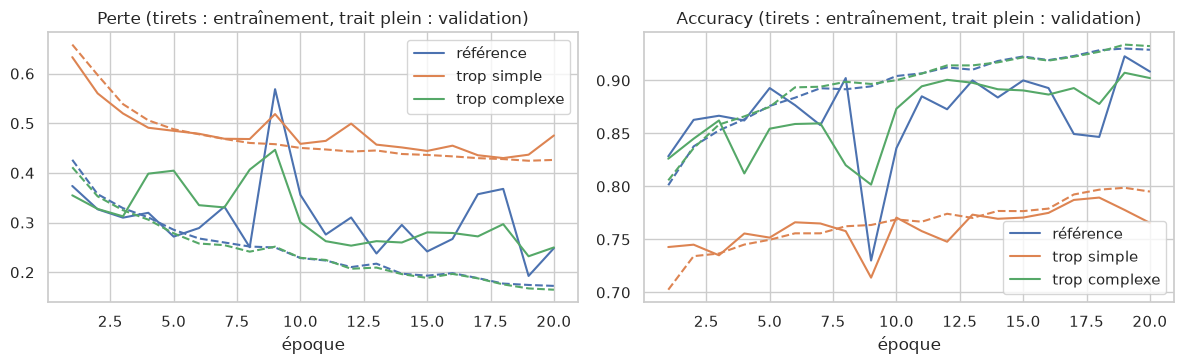

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for name, hist in cap_hist.items():
    line, = axes[0].plot(hist["epoch"], hist["loss"], ls="--")
    axes[0].plot(hist["epoch"], hist["val_loss"], color=line.get_color(), label=name)
    line, = axes[1].plot(hist["epoch"], hist["accuracy"], ls="--")
    axes[1].plot(hist["epoch"], hist["val_accuracy"], color=line.get_color(), label=name)
axes[0].set_title("Perte (tirets : entraînement, trait plein : validation)")
axes[1].set_title("Accuracy (tirets : entraînement, trait plein : validation)")
for ax in axes:
    ax.set_xlabel("époque")
    ax.legend()
plt.tight_layout()
plt.show()

### 7.2 Courbe d'apprentissage : que se passe-t-il avec plus de données ?
Nous entraînons le modèle de référence sur une part croissante du jeu d'entraînement (stratifiée par classe) et
comparons l'accuracy d'entraînement et de validation en fin d'entraînement. L'accuracy de validation d'une seule
époque peut bouger de plusieurs points d'une époque à l'autre (section 6), donc chaque point est la moyenne des
trois dernières époques. Un **grand écart qui se referme quand les données augmentent** signale de la variance,
que davantage d'images réduirait. Deux courbes **proches mais basses** signalent du biais, que plus de données ne
corrigera pas.

,n_train,acc. entraînement,acc. validation
fraction,,,
0.10,840,0.871,0.819
0.25,2100,0.908,0.848
0.50,4200,0.921,0.806
1.00,8400,0.927,0.905


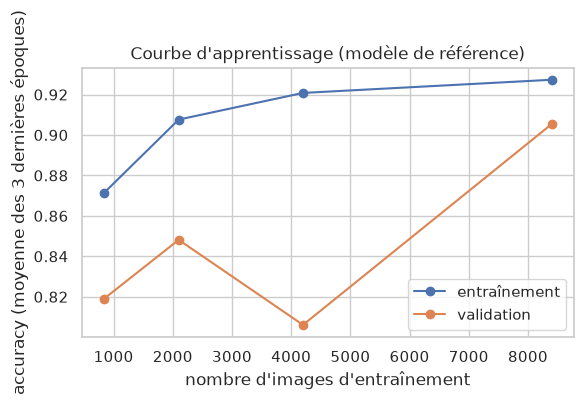

In [21]:
from sklearn.model_selection import train_test_split

curve_rows = []
for frac in (0.1, 0.25, 0.5, 1.0):
    if frac < 1.0:
        keep, _ = train_test_split(np.arange(len(ytr)), train_size=frac, stratify=mtr["source"], random_state=config.SEED)
    else:
        keep = np.arange(len(ytr))
    sub = {"train": (Xtr[keep], ytr[keep], mtr.iloc[keep]), "val": FINAL_SPLIT["val"], "test": FINAL_SPLIT["test"]}
    _, hist, _ = run(sub, EPOCHS["curve"])
    end = hist.tail(3)                                   # moyenne des trois dernières époques
    curve_rows.append({"fraction": frac, "n_train": len(keep), "acc. entraînement": end["accuracy"].mean(),
                       "acc. validation": end["val_accuracy"].mean()})
curve_df = pd.DataFrame(curve_rows).set_index("fraction")
display(curve_df)

fig, ax = plt.subplots(figsize=(6, 3.8))
ax.plot(curve_df["n_train"], curve_df["acc. entraînement"], marker="o", label="entraînement")
ax.plot(curve_df["n_train"], curve_df["acc. validation"], marker="o", label="validation")
ax.set_xlabel("nombre d'images d'entraînement")
ax.set_ylabel("accuracy (moyenne des 3 dernières époques)")
ax.set_title("Courbe d'apprentissage (modèle de référence)")
ax.legend()
plt.tight_layout()
plt.show()

In [22]:
small, big = curve_df.iloc[0], curve_df.iloc[-1]
delta_big = cap_df.loc["trop complexe", "acc. validation"] - cap_df.loc["référence", "acc. validation"]
ratio_big = cap_df.loc["trop complexe", "paramètres"] / cap_df.loc["référence", "paramètres"]
delta_small = cap_df.loc["trop simple", "acc. validation"] - cap_df.loc["référence", "acc. validation"]
capacity_note = (
    f" Multiplier le nombre de paramètres par {ratio_big:.1f} change l'accuracy de validation de {delta_big:+.3f}"
    + (" : le modèle de référence a donc déjà assez de capacité pour cette tâche." if abs(delta_big) < 0.01
       else (" : le plus grand modèle fait donc mieux." if delta_big > 0 else " : le plus grand modèle fait donc moins bien."))
    + f" Le modèle « trop simple » est à {delta_small:+.3f} du modèle de référence."
)
display(Markdown(
    "**Résultats.** "
    f"Capacité : le modèle « trop simple » ({milliers(cap_df.loc['trop simple', 'paramètres'])} paramètres) atteint "
    f"{cap_df.loc['trop simple', 'acc. validation']:.3f} en validation, le modèle de référence "
    f"({milliers(cap_df.loc['référence', 'paramètres'])}) {cap_df.loc['référence', 'acc. validation']:.3f} et le modèle "
    f"« trop complexe » ({milliers(cap_df.loc['trop complexe', 'paramètres'])}) "
    f"{cap_df.loc['trop complexe', 'acc. validation']:.3f}. "
    f"Diagnostics : trop simple, *{cap_df.loc['trop simple', 'diagnostic']}* ; référence, "
    f"*{cap_df.loc['référence', 'diagnostic']}* ; trop complexe, *{cap_df.loc['trop complexe', 'diagnostic']}*. "
    f"Courbe d'apprentissage : avec {milliers(small['n_train'])} images, l'écart entraînement-validation est de "
    f"{small['acc. entraînement'] - small['acc. validation']:+.3f} ; avec {milliers(big['n_train'])} images, il est de "
    f"{big['acc. entraînement'] - big['acc. validation']:+.3f}."
    + capacity_note
))

**Résultats.** Capacité : le modèle « trop simple » (485 paramètres) atteint 0.766 en validation, le modèle de référence (106 481) 0.908 et le modèle « trop complexe » (455 905) 0.902. Diagnostics : trop simple, *biais élevé (sous-apprentissage)* ; référence, *variance élevée (sur-apprentissage)* ; trop complexe, *équilibré (pas de problème net de biais ou de variance)*. Courbe d'apprentissage : avec 840 images, l'écart entraînement-validation est de +0.052 ; avec 8 400 images, il est de +0.022. Multiplier le nombre de paramètres par 4.3 change l'accuracy de validation de -0.006 : le modèle de référence a donc déjà assez de capacité pour cette tâche. Le modèle « trop simple » est à -0.143 du modèle de référence.

**Interprétation.** Un écart qui diminue quand le nombre d'images augmente veut dire que nous sommes dans un
régime de **variance** : plus de données, ou de la régularisation, aideront. Un modèle dont l'accuracy
d'entraînement est elle-même trop basse est dans un régime de **biais** : il lui faut plus de capacité ou plus
d'époques, pas plus de données. Les chiffres ci-dessus indiquent dans quel régime se trouve chaque configuration.

## 8. Améliorer le compromis biais / variance

### 8.1 Méthodes disponibles

| Méthode | Idée | Effet attendu | Utilisée ici |
|---|---|---|---|
| **Plus de données** | plus d'exemples, moins d'apprentissage par cœur | baisse de la variance | limitée à l'échantillon (voir 7.2) |
| **Augmentation de données** | transformations aléatoires (miroir, rotation, zoom, contraste) à chaque époque : le réseau ne voit jamais deux fois exactement la même image | baisse de la variance | oui |
| **Dropout** | désactive au hasard une part des neurones à chaque pas, ce qui empêche leur co-adaptation | baisse de la variance | oui (0.4) |
| **Régularisation L2** (*weight decay*) | ajoute $\lambda \sum w^2$ à la perte : les grands poids sont pénalisés et le modèle devient plus lisse | baisse de la variance | oui ($\lambda = 10^{-4}$) |
| **Early stopping** | arrête l'entraînement quand la perte de validation ne s'améliore plus et restaure les meilleurs poids | baisse de la variance | oui (patience 5) |
| **Capacité réduite** | moins de couches ou de filtres | baisse de la variance, hausse du biais | voir 7.1 |
| **BatchNormalization** | normalise les activations ; léger effet régularisant | stabilité | déjà dans le réseau |
| **Plus de capacité ou d'époques** | plus de filtres, entraînement plus long | baisse du biais | voir 7.1 |
| **Taux d'apprentissage adaptatif** | baisser le pas quand la validation stagne (`ReduceLROnPlateau`) | convergence plus fine | non utilisé |
| **Transfer learning** | partir d'un réseau pré-entraîné sur ImageNet | baisse du biais et de la variance avec peu de données | section 10 |

### 8.2 Expériences
Même problème (étape 4), même graine. Chaque technique est essayée **seule**, puis **toutes ensemble** (avec early
stopping). L'early stopping reçoit un budget d'époques plus grand puisqu'il décide lui-même quand s'arrêter.

In [23]:
IMPROVEMENTS = {
    "référence": dict(kwargs=dict(), epochs=EPOCHS["main"], es=False),
    "+ augmentation": dict(kwargs=dict(augmentation=True), epochs=EPOCHS["main"], es=False),
    "+ dropout 0.4": dict(kwargs=dict(dropout=0.4), epochs=EPOCHS["main"], es=False),
    "+ L2 1e-4": dict(kwargs=dict(l2=1e-4), epochs=EPOCHS["main"], es=False),
    "+ early stopping": dict(kwargs=dict(), epochs=EPOCHS["improve"], es=True),
    "tout combiné": dict(kwargs=dict(augmentation=True, dropout=0.4, l2=1e-4), epochs=EPOCHS["improve"], es=True),
}
imp_hist, imp_models, imp_rows = {}, {}, []
for name, cfg in IMPROVEMENTS.items():
    if name == "référence":
        model, hist, sec = baseline_model, baseline_hist, baseline_sec
    else:
        model, hist, sec = run(FINAL_SPLIT, cfg["epochs"], early_stopping=cfg["es"], patience=5, **cfg["kwargs"])
    imp_hist[name], imp_models[name] = hist, model
    d = evaluation.diagnose_fit(hist, restored_best=cfg["es"])  # early stopping : poids restaurés = meilleure époque
    val_metrics = model.evaluate(data.make_dataset(Xva, yva), verbose=0, return_dict=True)  # poids du modèle FINAL
    imp_rows.append({"configuration": name, "époques effectuées": len(hist), "époque retenue": d["kept_epoch"],
                     "acc. entraînement (époque retenue)": d["train_acc"],
                     "écart entr.-val. (époque retenue)": d["gap_acc"], "perte val. (modèle final)": val_metrics["loss"],
                     "acc. val. (modèle final)": val_metrics["accuracy"], "diagnostic": d["verdict"],
                     "temps (s)": round(sec)})
imp_df = pd.DataFrame(imp_rows).set_index("configuration")
display(imp_df)

,époques effectuées,époque retenue,acc. entraînement (époque retenue),écart entr.-val. (époque retenue),perte val. (modèle final),acc. val. (modèle final),diagnostic,temps (s)
configuration,,,,,,,,
référence,20,20,0.929,0.021,0.248,0.908,variance élevée (sur-apprentissage),15
+ augmentation,20,20,0.904,0.008,0.232,0.896,équilibré (pas de problème net de biais ou de ...,27
+ dropout 0.4,20,20,0.917,0.012,0.229,0.906,équilibré (pas de problème net de biais ou de ...,16
+ L2 1e-4,20,20,0.926,0.042,0.294,0.884,variance élevée (sur-apprentissage),16
+ early stopping,24,19,0.930,0.010,0.209,0.920,équilibré (pas de problème net de biais ou de ...,18
tout combiné,12,7,0.861,-0.015,0.315,0.877,biais élevé (sous-apprentissage),16


In [24]:
base = imp_df.loc["référence"]
others = imp_df.drop(index="référence")
lower_loss = others.index[others["perte val. (modèle final)"] < base["perte val. (modèle final)"]].tolist()
higher_acc = others.index[others["acc. val. (modèle final)"] > base["acc. val. (modèle final)"]].tolist()
display(Markdown("**Résultats.** Par rapport au modèle de référence (perte de validation "
    f"{base['perte val. (modèle final)']:.3f}, accuracy {base['acc. val. (modèle final)']:.3f}), "
    f"perte de validation plus basse : {', '.join(lower_loss) or 'aucune'} ; "
    f"accuracy de validation plus haute : {', '.join(higher_acc) or 'aucune'}. "
    + (f"Les configurations avec early stopping disposent de {EPOCHS['improve']} époques au lieu de {EPOCHS['main']}, "
       "les budgets ne sont donc pas identiques." if EPOCHS["improve"] != EPOCHS["main"] else "")))

**Résultats.** Par rapport au modèle de référence (perte de validation 0.248, accuracy 0.908), perte de validation plus basse : + augmentation, + dropout 0.4, + early stopping ; accuracy de validation plus haute : + early stopping. Les configurations avec early stopping disposent de 25 époques au lieu de 20, les budgets ne sont donc pas identiques.

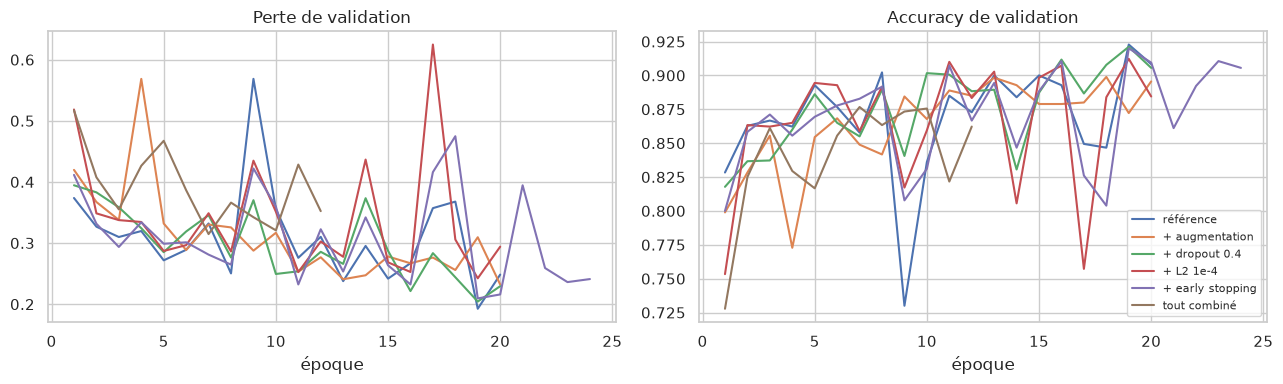

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for name, hist in imp_hist.items():
    axes[0].plot(hist["epoch"], hist["val_loss"], label=name)
    axes[1].plot(hist["epoch"], hist["val_accuracy"], label=name)
axes[0].set_title("Perte de validation")
axes[1].set_title("Accuracy de validation")
for ax in axes:
    ax.set_xlabel("époque")
axes[0].set_ylim(top=min(1.5, axes[0].get_ylim()[1]))
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

In [26]:
best_name = imp_df["perte val. (modèle final)"].idxmin()
display(Markdown(
    f"**Choix du modèle (jeu de validation uniquement).** La configuration de plus faible perte de validation est "
    f"**{best_name}** (perte {imp_df.loc[best_name, 'perte val. (modèle final)']:.4f}, "
    f"accuracy {imp_df.loc[best_name, 'acc. val. (modèle final)']:.3f})"
    + (" ; aucune technique n'a fait baisser la perte de validation lors de cette exécution"
       + (", ce qui est cohérent avec un modèle de référence sans problème net de variance"
          if imp_df.loc["référence", "diagnostic"].startswith("équilibré") else "") + ". "
       if best_name == "référence" else
       f" ; le modèle de référence obtient {imp_df.loc['référence', 'perte val. (modèle final)']:.4f} / "
       f"{imp_df.loc['référence', 'acc. val. (modèle final)']:.3f}. ")
    + "C'est ce CNN que nous évaluons sur les jeux de test dans la section suivante."
))
final_model = imp_models[best_name]
final_hist = imp_hist[best_name]

**Choix du modèle (jeu de validation uniquement).** La configuration de plus faible perte de validation est **+ early stopping** (perte 0.2094, accuracy 0.920) ; le modèle de référence obtient 0.2484 / 0.908. C'est ce CNN que nous évaluons sur les jeux de test dans la section suivante.

Courbes du modèle retenu (entraînement et validation, perte et accuracy) :

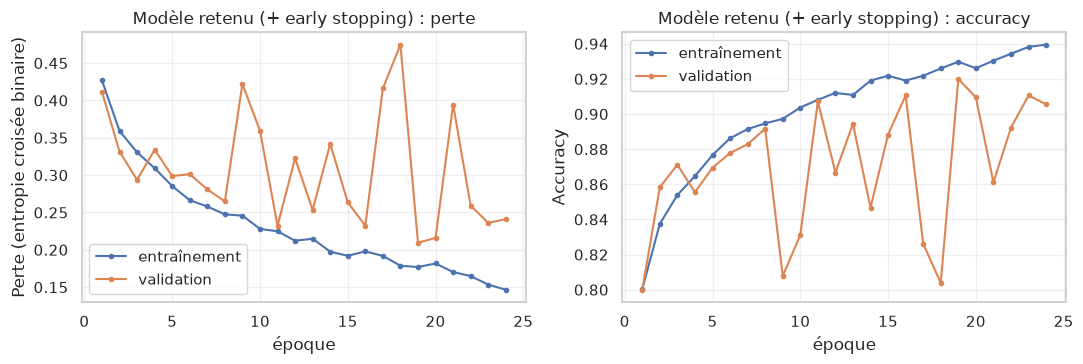

Diagnostic du modèle retenu (époque retenue : 19) : accuracy d'entraînement 0.930, validation 0.920, soit **équilibré (pas de problème net de biais ou de variance)**.

In [27]:
evaluation.plot_history(final_hist, f"Modèle retenu ({best_name})")
plt.show()
d = evaluation.diagnose_fit(final_hist, restored_best=IMPROVEMENTS[best_name]["es"])
kept_kwargs = IMPROVEMENTS[best_name]["kwargs"]
reg_note = (" À noter : avec dropout et augmentation, l'accuracy d'entraînement est mesurée avec ces perturbations "
            "actives, elle est donc plus basse qu'elle ne le serait en inférence."
            if ("augmentation" in kept_kwargs or "dropout" in kept_kwargs) else "")
display(Markdown(
    f"Diagnostic du modèle retenu (époque retenue : {d['kept_epoch']}) : accuracy d'entraînement {d['train_acc']:.3f}, "
    f"validation {d['val_acc']:.3f}, soit **{d['verdict']}**." + reg_note
))

## 9. Évaluation finale

Nous utilisons maintenant le jeu **`test`** (équilibré, jamais vu) et le **jeu de test étendu `ext`**
(déséquilibré, plus proche d'une vraie archive) avec le modèle retenu en section 8. Les deux ne servent qu'à la
mesure, jamais à entraîner, à choisir un modèle ou à fixer un seuil.

In [28]:
METRIC_NAMES = {"accuracy": "accuracy", "balanced_accuracy": "acc. équilibrée", "precision": "précision",
                "recall": "rappel", "f1": "F1", "roc_auc": "ROC-AUC", "tp": "VP", "fp": "FP", "fn": "FN", "tn": "VN"}
Xe, ye, me = data.select(X, meta, "ext")
results, probas = {}, {}
for label, (Xs, ys, ms) in {"test (équilibré)": (Xte, yte, mte), "ext (réaliste)": (Xe, ye, me)}.items():
    probas[label] = modeling.predict_proba(final_model, Xs)
    results[label] = evaluation.evaluate_binary(ys, probas[label])
res_df = pd.DataFrame(results).T
display(res_df[list(METRIC_NAMES)].rename(columns=METRIC_NAMES))
print(f"Part de photos : test {yte.mean():.1%} | ext {ye.mean():.1%}")
print("VP / FP / FN / VN : vrais positifs, faux positifs, faux négatifs, vrais négatifs (positif = photo)")

,accuracy,acc. équilibrée,précision,rappel,F1,ROC-AUC,VP,FP,FN,VN
test (équilibré),0.911,0.911,0.887,0.942,0.914,0.967,848.0,108.0,52.0,792.0
ext (réaliste),0.923,0.934,0.756,0.953,0.843,0.980,953.0,308.0,47.0,3297.0


Part de photos : test 50.0% | ext 21.7%
VP / FP / FN / VN : vrais positifs, faux positifs, faux négatifs, vrais négatifs (positif = photo)


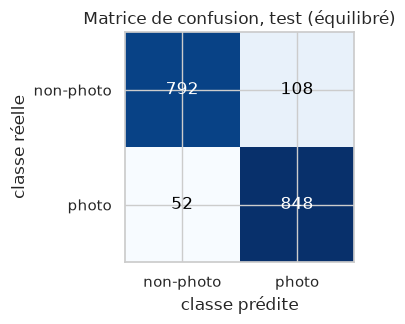

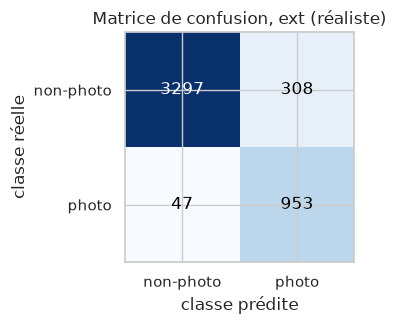

In [29]:
for label, (Xs, ys, ms) in {"test (équilibré)": (Xte, yte, mte), "ext (réaliste)": (Xe, ye, me)}.items():
    evaluation.plot_confusion(ys, probas[label], title=f"Matrice de confusion, {label}")
    plt.show()

### 9.1 Où le modèle se trompe-t-il ?
Accuracy par type d'image sur le jeu de test étendu (le plus grand) :

,source,n,accuracy
0,Painting,999,0.791
1,Schematics,1000,0.901
2,Photo,1000,0.953
3,Sketch,606,1.000
4,Text,1000,1.000


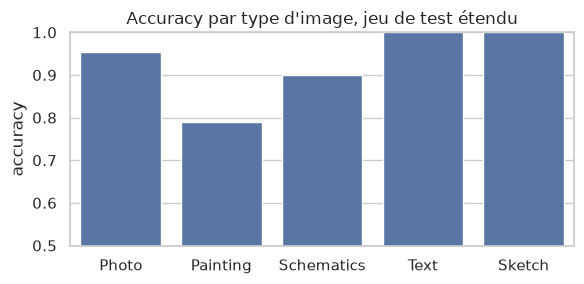

In [30]:
per_src_ext = evaluation.per_source_accuracy(me, probas["ext (réaliste)"])
display(per_src_ext)
fig, ax = plt.subplots(figsize=(6, 3))
sns.barplot(data=per_src_ext, x="source", y="accuracy", order=config.CLASSES, ax=ax)
ax.set_ylim(0.5, 1.0)
ax.set_xlabel("")
ax.set_title("Accuracy par type d'image, jeu de test étendu")
plt.tight_layout()
plt.show()

**Faux positifs** : des non-photos prises pour des photos, les plus sûres d'abord. Ce sont les erreurs coûteuses
pour TouNum, car elles partent dans le module de captioning.

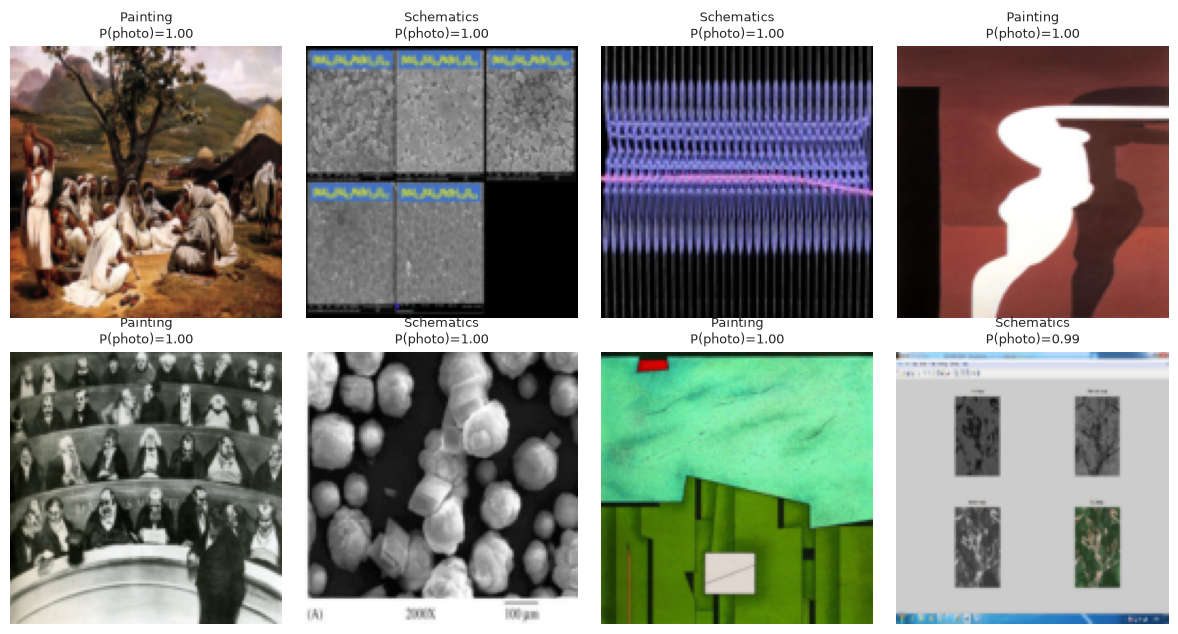

In [31]:
fig = evaluation.show_errors(Xe, me, probas["ext (réaliste)"], kind="fp", n=8)
if fig is None:
    print("Aucun faux positif sur le jeu de test étendu.")
else:
    plt.show()

**Faux négatifs** : des photos rejetées, les plus sûres d'abord.

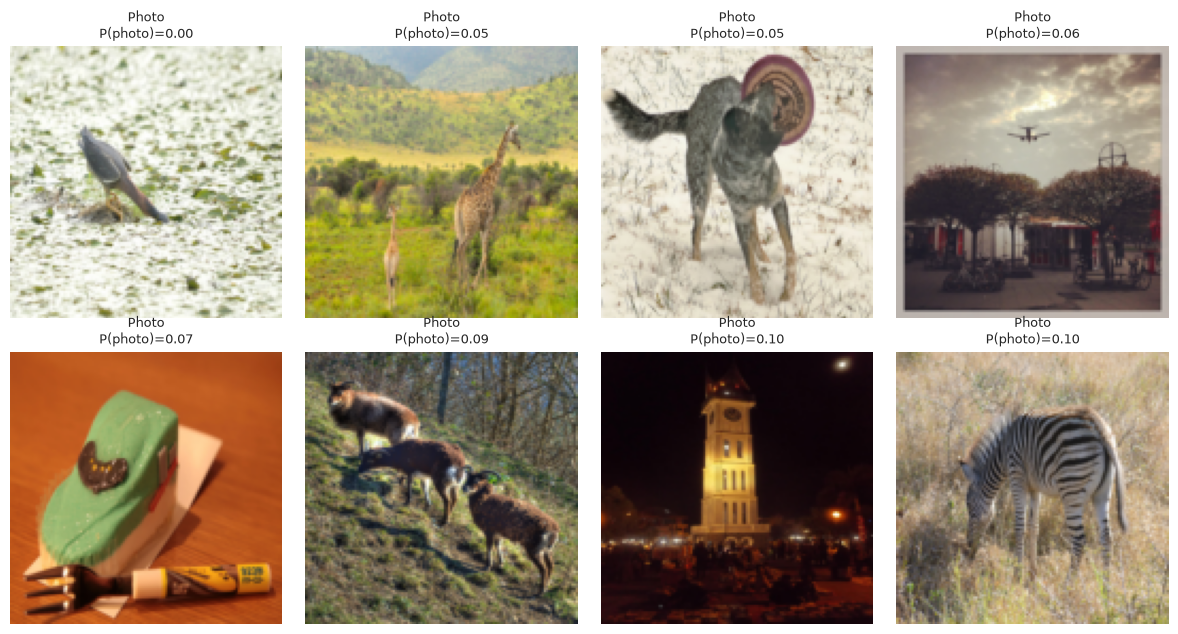

In [32]:
fig = evaluation.show_errors(Xe, me, probas["ext (réaliste)"], kind="fn", n=8)
if fig is None:
    print("Aucun faux négatif sur le jeu de test étendu.")
else:
    plt.show()

### 9.2 Choix du seuil de décision
0.5 n'est qu'une valeur par défaut. Pour TouNum, **laisser passer une non-photo** (faux positif, précision plus
basse) et **perdre une photo** (faux négatif, rappel plus bas) n'ont pas le même coût : le seuil est donc une
décision métier. Le tableau ci-dessous est descriptif : il montre comment précision et rappel évoluent avec le
seuil sur le jeu de test étendu, où les photos sont minoritaires. Un seuil de production devrait être fixé sur des
données de validation (ou de nouvelles données) puis confirmé, pas réglé sur ce tableau, qui est un jeu de mesure.

,précision,rappel,F1,faux positifs,faux négatifs
seuil,,,,,
0.1,0.574,0.992,0.727,736,8
0.3,0.680,0.973,0.800,458,27
0.5,0.756,0.953,0.843,308,47
0.7,0.818,0.911,0.862,203,89
0.9,0.882,0.801,0.840,107,199


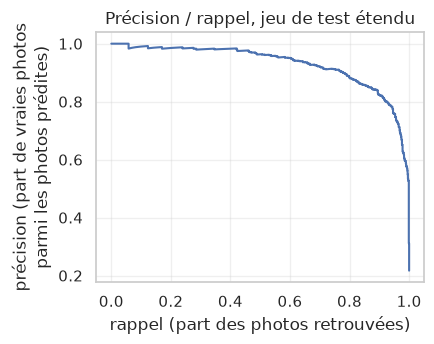

In [33]:
rows = []
for thr in (0.1, 0.3, 0.5, 0.7, 0.9):
    r = evaluation.evaluate_binary(ye, probas["ext (réaliste)"], threshold=thr)
    rows.append({"seuil": thr, "précision": r["precision"], "rappel": r["recall"], "F1": r["f1"],
                 "faux positifs": r["fp"], "faux négatifs": r["fn"]})
display(pd.DataFrame(rows).set_index("seuil"))
evaluation.plot_precision_recall(ye, probas["ext (réaliste)"], "Précision / rappel, jeu de test étendu")
plt.show()

In [34]:
res_t, res_e = results["test (équilibré)"], results["ext (réaliste)"]
worst = per_src_ext.iloc[0]
display(Markdown(
    f"**Résultats.** Jeu de test équilibré : accuracy **{res_t['accuracy']:.3f}**, F1 **{res_t['f1']:.3f}**, "
    f"ROC-AUC **{res_t['roc_auc']:.3f}**. Jeu de test étendu (environ {ye.mean():.0%} de photos) : accuracy "
    f"**{res_e['accuracy']:.3f}**, précision **{res_e['precision']:.3f}**, rappel **{res_e['recall']:.3f}**, "
    f"F1 **{res_e['f1']:.3f}**. Le type d'image le moins bien classé est **{worst['source']}** "
    f"(accuracy {worst['accuracy']:.3f}). "
    + ("La précision est plus basse sur le jeu étendu parce que les photos y sont minoritaires : à taux de faux "
       "positifs égal, les faux positifs pèsent plus face à moins de vrais positifs. C'est la métrique à surveiller "
       "en production."
       if res_e["precision"] < res_t["precision"] - 0.01
       else "La précision tient malgré le déséquilibre des classes du jeu étendu.")
))

**Résultats.** Jeu de test équilibré : accuracy **0.911**, F1 **0.914**, ROC-AUC **0.967**. Jeu de test étendu (environ 22% de photos) : accuracy **0.923**, précision **0.756**, rappel **0.953**, F1 **0.843**. Le type d'image le moins bien classé est **Painting** (accuracy 0.791). La précision est plus basse sur le jeu étendu parce que les photos y sont minoritaires : à taux de faux positifs égal, les faux positifs pèsent plus face à moins de vrais positifs. C'est la métrique à surveiller en production.

### 9.3 Sauvegarde de notre CNN
Le modèle contient son propre prétraitement (`Rescaling`) : il lui suffit d'images 128×128×3 en `uint8`.
`data.load_image` fait la conversion (RGB et redimensionnement) depuis n'importe quel fichier jpg ou png.

In [35]:
SAVE_DIR = Path(tempfile.gettempdir()) / "tounum_quick" if QUICK else config.MODELS_DIR   # QUICK ne touche jamais models/
SAVE_DIR.mkdir(parents=True, exist_ok=True)


def save_and_check(model, filename):
    """Sauvegarde un modèle, le recharge et vérifie que les deux donnent les mêmes prédictions."""
    path = SAVE_DIR / filename
    model.save(path)
    reloaded = keras.models.load_model(path)
    assert np.allclose(reloaded.predict(Xte[:32], verbose=0), model.predict(Xte[:32], verbose=0), atol=1e-5)
    shown = path.relative_to(config.PROJECT_ROOT) if path.is_relative_to(config.PROJECT_ROOT) else path
    print(f"Sauvegardé : {shown} ({path.stat().st_size / 1e6:.1f} Mo), rechargement vérifié.")
    return reloaded


save_and_check(final_model, "photo_cnn.keras")


def predict_photo(model, paths, threshold=0.5):
    """Classe des fichiers image. Renvoie un DataFrame (fichier, P(photo), est_photo)."""
    batch = np.stack([data.load_image(p) for p in paths])
    proba = modeling.predict_proba(model, batch)
    return pd.DataFrame({"fichier": [Path(p).name for p in paths], "P(photo)": proba.round(3),
                         "est_photo": proba >= threshold})

Sauvegardé : models/photo_cnn.keras (1.4 Mo), rechargement vérifié.


## 10. Comparaison avec un réseau pré-entraîné (MobileNetV2)

Pour situer notre architecture, nous la comparons à **MobileNetV2** pré-entraîné sur ImageNet (plus d'un million
d'images), utilisé comme extracteur de features **gelé** : seule la tête (une couche `Dense` sigmoïde) est
entraînée. C'est du *transfer learning*. Les poids ImageNet sont téléchargés à la première utilisation.

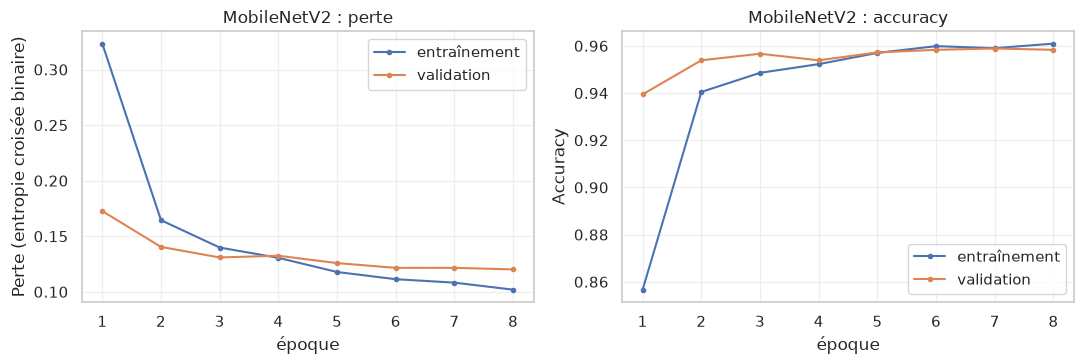

,paramètres,entraînables,accuracy val,F1 val,AUC val,accuracy test,F1 test,AUC test,accuracy ext,F1 ext,AUC ext,acc. ext Painting,temps d'entraînement (s)
modèle,,,,,,,,,,,,,
notre CNN (+ early stopping),106481,106001,0.920,0.923,0.976,0.911,0.914,0.967,0.923,0.843,0.980,0.791,18
MobileNetV2 gelé + tête,2259265,1281,0.958,0.958,0.991,0.946,0.946,0.988,0.971,0.936,0.994,0.938,14


In [36]:
def summarize(model, name):
    row = {"modèle": name, "paramètres": model.count_params(),
           "entraînables": int(sum(np.prod(w.shape) for w in model.trainable_weights))}
    for label, (Xs, ys, ms) in {"val": (Xva, yva, mva), "test": (Xte, yte, mte), "ext": (Xe, ye, me)}.items():
        p = modeling.predict_proba(model, Xs)
        r = evaluation.evaluate_binary(ys, p)
        row[f"accuracy {label}"], row[f"F1 {label}"], row[f"AUC {label}"] = r["accuracy"], r["f1"], r["roc_auc"]
        if label == "ext":
            acc = evaluation.per_source_accuracy(ms, p).set_index("source")["accuracy"]
            row["acc. ext Painting"] = acc.get("Painting", np.nan)
    return row


compare_rows = [summarize(final_model, f"notre CNN ({best_name})")]
mnet = None
try:
    mnet = modeling.build_mobilenet()
    keras.utils.set_random_seed(config.SEED)
    t0 = time.perf_counter()
    mnet_hist = modeling.train(mnet, data.make_dataset(Xtr, ytr, shuffle=True), data.make_dataset(Xva, yva),
                               epochs=EPOCHS["mobilenet"], class_weight=data.class_weights(ytr), verbose=0)
    mnet_sec = time.perf_counter() - t0
    row = summarize(mnet, "MobileNetV2 gelé + tête")
    row["temps d'entraînement (s)"] = round(mnet_sec)
    compare_rows.append(row)
    evaluation.plot_history(mnet_hist, "MobileNetV2")
    plt.show()
except Exception as exc:  # par exemple pas d'accès réseau pour télécharger les poids ImageNet
    mnet = None
    print(f"Comparaison avec MobileNetV2 ignorée : {type(exc).__name__}: {exc}")
compare_rows[0]["temps d'entraînement (s)"] = round(imp_df.loc[best_name, "temps (s)"])
compare_df = pd.DataFrame(compare_rows).set_index("modèle")
display(compare_df)

In [37]:
production_model, production_name = final_model, "notre CNN"
if len(compare_df) == 2:
    a, b = compare_df.iloc[0], compare_df.iloc[1]
    gain = b["accuracy val"] - a["accuracy val"]  # la décision se fait sur la VALIDATION ; test et ext sont indicatifs
    ratio = b["paramètres"] / a["paramètres"]
    if gain > 0.02:
        production_model, production_name = mnet, "MobileNetV2"
        verdict = (f"MobileNetV2 a une meilleure accuracy de validation (+{gain:.3f}) avec {ratio:.0f} fois plus de "
                   "paramètres, dont un millier seulement sont entraînés. Il devient le modèle de production. "
                   "Notre CNN reste disponible comme modèle plus léger, qui ne dépend pas de poids pré-entraînés.")
    elif gain < -0.02:
        verdict = (f"Notre CNN a une meilleure accuracy de validation (+{-gain:.3f}) avec {ratio:.0f} fois moins de "
                   "paramètres. Il reste le modèle de production.")
    else:
        verdict = ("Les accuracies de validation sont proches (écart inférieur à 0.02) : notre CNN, plus léger, reste "
                   "le modèle de production.")
    display(Markdown(
        f"**Résultats.** Notre CNN : {milliers(a['paramètres'])} paramètres, accuracy {a['accuracy val']:.3f} "
        f"(validation) / {a['accuracy test']:.3f} (test) / {a['accuracy ext']:.3f} (ext), peintures "
        f"{a['acc. ext Painting']:.3f}. MobileNetV2 : {milliers(b['paramètres'])} paramètres "
        f"({milliers(b['entraînables'])} entraînables), accuracy {b['accuracy val']:.3f} / {b['accuracy test']:.3f} / "
        f"{b['accuracy ext']:.3f}, peintures {b['acc. ext Painting']:.3f}. {verdict} La décision repose sur le jeu de "
        "validation ; les chiffres de test et d'ext sont donnés à titre indicatif."
    ))
else:
    verdict = "La comparaison avec MobileNetV2 n'a pas pu tourner : notre CNN est le modèle de production."
    print(verdict)

**Résultats.** Notre CNN : 106 481 paramètres, accuracy 0.920 (validation) / 0.911 (test) / 0.923 (ext), peintures 0.791. MobileNetV2 : 2 259 265 paramètres (1 281 entraînables), accuracy 0.958 / 0.946 / 0.971, peintures 0.938. MobileNetV2 a une meilleure accuracy de validation (+0.038) avec 21 fois plus de paramètres, dont un millier seulement sont entraînés. Il devient le modèle de production. Notre CNN reste disponible comme modèle plus léger, qui ne dépend pas de poids pré-entraînés. La décision repose sur le jeu de validation ; les chiffres de test et d'ext sont donnés à titre indicatif.

### 10.1 Sauvegarde du modèle de production
Le modèle de production est sauvegardé dans `models/photo_classifier.keras`. C'est ce fichier que charge le
pipeline complet du livrable 3. Comme notre CNN, il prend des images brutes 128×128×3 en `uint8`.

In [38]:
classifier = save_and_check(production_model, "photo_classifier.keras")
demo = me.sample(8, random_state=config.SEED)
out = predict_photo(classifier, demo["path"].tolist())
out["type réel"] = demo["source"].to_numpy()
display(out)

Sauvegardé : models/photo_classifier.keras (9.6 Mo), rechargement vérifié.


,fichier,P(photo),est_photo,type réel
0,m1-002-01-sz1.jpg,0.006,False,Sketch
1,photo_8226.jpg,1.000,True,Photo
2,293_1_1_sz1.jpg,0.018,False,Sketch
3,photo_1232.jpg,0.999,True,Photo
4,text_08045.jpg,0.001,False,Text
5,painting_01181.jpg,0.003,False,Painting
6,painting_06920.jpg,0.007,False,Painting
7,painting_03269.jpg,0.129,False,Painting


## 11. Conclusion, limites et suites

### Chiffres clés
Les chiffres ci-dessous sont recalculés à chaque exécution à partir des résultats des sections précédentes.

In [39]:
worst_src = per_src_ext.iloc[0]
display(Markdown(
    f"**Synthèse.** Configuration retenue pour notre CNN (choisie en validation) : **{best_name}**, "
    f"époque retenue {d['kept_epoch']}. Accuracy : validation **{imp_df.loc[best_name, 'acc. val. (modèle final)']:.3f}**, "
    f"test **{res_t['accuracy']:.3f}**, test étendu **{res_e['accuracy']:.3f}**. "
    f"Sur le test étendu : précision **{res_e['precision']:.3f}**, rappel **{res_e['recall']:.3f}**. "
    f"Type d'image le moins bien classé (test étendu) : **{worst_src['source']}** (accuracy {worst_src['accuracy']:.3f}). "
    f"Modèle de production : **{production_name}**. {verdict}"
))

**Synthèse.** Configuration retenue pour notre CNN (choisie en validation) : **+ early stopping**, époque retenue 19. Accuracy : validation **0.920**, test **0.911**, test étendu **0.923**. Sur le test étendu : précision **0.756**, rappel **0.953**. Type d'image le moins bien classé (test étendu) : **Painting** (accuracy 0.791). Modèle de production : **MobileNetV2**. MobileNetV2 a une meilleure accuracy de validation (+0.038) avec 21 fois plus de paramètres, dont un millier seulement sont entraînés. Il devient le modèle de production. Notre CNN reste disponible comme modèle plus léger, qui ne dépend pas de poids pré-entraînés.

### Ce que nous avons construit
1. Un **workflow reproductible, des archives brutes jusqu'au modèle entraîné** : inventaire des archives,
   échantillonnage disjoint, extraction sélective, normalisation (RGB, 128×128), cache, découpage stratifié.
2. **Notre propre CNN d'environ 106 000 paramètres**, entraîné avec Adam sur l'entropie croisée binaire, vérifié
   sur des problèmes de difficulté croissante (section 4) et comparé à un réseau pré-entraîné (section 10).
3. Une **analyse biais / variance** chiffrée (sections 6 à 8) et une comparaison des techniques de régularisation.
4. Une **évaluation sur des jeux de test jamais utilisés pour l'entraînement ni pour le choix du modèle**, l'un
   équilibré et l'autre réaliste (section 9), avec une analyse des erreurs et une discussion du seuil.
5. Des **modèles sauvegardés** : `models/photo_cnn.keras` (notre CNN) et `models/photo_classifier.keras` (modèle
   de production, utilisé par le pipeline du livrable 3), ainsi qu'une fonction d'inférence (`predict_photo`).

### Limites
- **Taille de l'échantillon** : 12 000 images de modélisation sur environ 41 400. Entraîner sur l'ensemble pourrait
  faire un peu mieux. Les effectifs se règlent dans `config.py`.
- **Résolution 128×128 et déformation** : les détails fins sont perdus (ils aident à distinguer une peinture
  réaliste d'une photo) et les pages allongées sont déformées.
- **Ce qui compte comme « photo »** : l'étiquette vient de l'archive d'origine. Une peinture hyperréaliste ou une
  photo très retouchée restent ambiguës, même pour une personne, et les erreurs d'étiquetage dans les archives
  plafonnent l'accuracy atteignable.
- **Généralisation** : le modèle est évalué sur des images issues des mêmes sources. Des images d'autres sources
  (autres scanners, autres types de documents, autres époques) peuvent faire baisser les résultats.
- **Qualité des images** : toutes les images d'entraînement sont assez propres. Le livrable 2 (débruitage) vérifie
  le comportement du filtre sur des images bruitées.
- **Reproductibilité** : de petites différences numériques sont possibles d'une machine à l'autre, et entre une
  exécution sur CPU et une sur GPU.

### Suites possibles
- Entraîner sur toutes les archives à une résolution plus élevée ;
- progresser sur les peintures réalistes (augmentation ciblée, fine-tuning des derniers blocs de MobileNetV2) ;
- fixer le seuil avec TouNum en fonction du coût de chaque type d'erreur (section 9.2) ;
- brancher ce filtre devant les modules de prétraitement et de captioning (livrables 2 et 3) et mesurer son effet
  de bout en bout ;
- surveiller la production (part d'images prédites comme photos, échantillon vérifié à la main) pour détecter une
  dérive des données.